In [6]:
# ==========================================
# SONG RECOMMENDATION SYSTEM - MLOPS PROJECT
# ==========================================

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import mlflow
import prefect
import fastapi
import evidently

# Project directory
ROOT = Path(r"E:\FDP_MLOPS\song_m1")

# Project folders
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
NOTEBOOK_DIR = ROOT / "notebooks"
OUTPUT_DIR = ROOT / "outputs"
REPORT_DIR = ROOT / "reports"
MODEL_DIR = ROOT / "models"
LOG_DIR = ROOT / "logs"

# Dataset location
DATA_FILE = RAW_DIR / "train_triplets.txt.zip"

# Create folders if missing
for folder in [
    RAW_DIR, PROCESSED_DIR, NOTEBOOK_DIR,
    OUTPUT_DIR, REPORT_DIR, MODEL_DIR, LOG_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("SONG RECOMMENDATION MLOPS PROJECT")
print("-" * 45)
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("MLflow:", mlflow.__version__)
print("Prefect:", prefect.__version__)
print("Evidently:", evidently.__version__)
print("Project directory:", ROOT)
print("Dataset available:", DATA_FILE.exists())

E:\FDP_MLOPS\song_m1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SONG RECOMMENDATION MLOPS PROJECT
---------------------------------------------
Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
NumPy: 2.4.6
Pandas: 3.0.6
Scikit-learn: 1.9.1
MLflow: 3.17.2
Prefect: 3.9.1
Evidently: 0.7.23
Project directory: E:\FDP_MLOPS\song_m1
Dataset available: True


In [7]:
# ==========================================
# STEP 8: LOAD MILLION SONG DATASET
# ==========================================

import pandas as pd
from pathlib import Path

DATA_FILE = Path(
    r"E:\FDP_MLOPS\song_m1\data\raw\train_triplets.txt.zip"
)

# Verify dataset exists
print("Dataset exists:", DATA_FILE.exists())
print("Dataset size (MB):", round(DATA_FILE.stat().st_size / (1024 * 1024), 2))

# Load first 500,000 interactions
df = pd.read_csv(
    DATA_FILE,
    compression="zip",
    sep="\t",
    header=None,
    names=["user_id", "song_id", "play_count"],
    nrows=500_000,
    dtype={
        "user_id": "string",
        "song_id": "string",
        "play_count": "int32"
    }
)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))

Dataset exists: True
Dataset size (MB): 488.41

Dataset loaded successfully!
Dataset shape: (500000, 3)


,user_id,song_id,play_count
0,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOAKIMP12A8C130995,1
1,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOAPDEY12A81C210A9,1
2,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBBMDR12A8C13253B,2
3,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBFNSP12AF72A0E22,1
4,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBFOVM12A58A7D494,1
5,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBNZDC12A6D4FC103,1
6,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBSUJE12A6D4F8CF5,2
7,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBVFZR12A6D4F8AE3,1
8,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBXALG12A8C13C108,1
9,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBXHDL12A81C204C0,1


In [8]:
print("DATASET INFORMATION")
print("-" * 40)

print("\nShape:")
print(df.shape)

print("\nColumn information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

print("\nFirst 5 records:")
display(df.head())

DATASET INFORMATION
----------------------------------------

Shape:
(500000, 3)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   user_id     500000 non-null  string
 1   song_id     500000 non-null  string
 2   play_count  500000 non-null  int32 
dtypes: int32(1), string(2)
memory usage: 37.2 MB
None

Missing values:
user_id       0
song_id       0
play_count    0
dtype: int64

Statistical summary:


,play_count
count,500000.000000
mean,2.902846
std,6.598049
min,1.000000
25%,1.000000
50%,1.000000
75%,3.000000
max,1890.000000



First 5 records:


,user_id,song_id,play_count
0,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOAKIMP12A8C130995,1
1,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOAPDEY12A81C210A9,1
2,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBBMDR12A8C13253B,2
3,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBFNSP12AF72A0E22,1
4,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBFOVM12A58A7D494,1


In [9]:
# ==========================================
# STEP 10: DATA CLEANING AND PREPROCESSING
# ==========================================

# Create a copy of original sample
df_clean = df.copy()

print("BEFORE CLEANING")
print("-" * 40)

print("Original shape:", df_clean.shape)
print("Missing values:\n", df_clean.isnull().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

# Remove leading/trailing spaces from IDs
df_clean["user_id"] = df_clean["user_id"].str.strip()
df_clean["song_id"] = df_clean["song_id"].str.strip()

# Convert play_count to numeric
df_clean["play_count"] = pd.to_numeric(
    df_clean["play_count"],
    errors="coerce"
)

# Remove missing and invalid records
df_clean = df_clean.dropna(
    subset=["user_id", "song_id", "play_count"]
)

# Remove empty IDs
df_clean = df_clean[
    (df_clean["user_id"] != "") &
    (df_clean["song_id"] != "")
]

# Keep only positive play counts
df_clean = df_clean[df_clean["play_count"] > 0]

# Remove exact duplicate interactions
df_clean = df_clean.drop_duplicates()

# Set appropriate data type
df_clean["play_count"] = df_clean["play_count"].astype("int32")

# Reset index
df_clean = df_clean.reset_index(drop=True)

print("\nAFTER CLEANING")
print("-" * 40)

print("Cleaned shape:", df_clean.shape)
print("Missing values:\n", df_clean.isnull().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

display(df_clean.head(10))

BEFORE CLEANING
----------------------------------------
Original shape: (500000, 3)
Missing values:
 user_id       0
song_id       0
play_count    0
dtype: int64
Duplicate rows: 0

AFTER CLEANING
----------------------------------------
Cleaned shape: (500000, 3)
Missing values:
 user_id       0
song_id       0
play_count    0
dtype: int64
Duplicate rows: 0


,user_id,song_id,play_count
0,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOAKIMP12A8C130995,1
1,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOAPDEY12A81C210A9,1
2,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBBMDR12A8C13253B,2
3,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBFNSP12AF72A0E22,1
4,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBFOVM12A58A7D494,1
5,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBNZDC12A6D4FC103,1
6,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBSUJE12A6D4F8CF5,2
7,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBVFZR12A6D4F8AE3,1
8,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBXALG12A8C13C108,1
9,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBXHDL12A81C204C0,1


In [10]:
# ==========================================
# STEP 11: DATASET STATISTICS
# ==========================================

total_interactions = len(df_clean)
total_users = df_clean["user_id"].nunique()
total_songs = df_clean["song_id"].nunique()

print("SONG DATASET STATISTICS")
print("=" * 45)

print("Total interactions:", total_interactions)
print("Unique users:", total_users)
print("Unique songs:", total_songs)

print(
    "Average play count:",
    round(df_clean["play_count"].mean(), 2)
)

print(
    "Maximum play count:",
    df_clean["play_count"].max()
)

print(
    "Minimum play count:",
    df_clean["play_count"].min()
)

SONG DATASET STATISTICS
Total interactions: 500000
Unique users: 10354
Unique songs: 108797
Average play count: 2.9
Maximum play count: 1890
Minimum play count: 1


In [11]:
# ==========================================
# STEP 12: SAVE CLEANED DATASET
# ==========================================

CLEAN_FILE = PROCESSED_DIR / "song_interactions_clean.csv"

df_clean.to_csv(CLEAN_FILE, index=False)

print("Cleaned dataset saved successfully!")
print("File:", CLEAN_FILE)
print("File size (MB):", round(CLEAN_FILE.stat().st_size / (1024 * 1024), 2))

Cleaned dataset saved successfully!
File: E:\FDP_MLOPS\song_m1\data\processed\song_interactions_clean.csv
File size (MB): 30.07


TOP 10 POPULAR SONGS


,song_id,total_plays
0,SOBONKR12A58A7A7E0,7115
1,SOAUWYT12A81C206F1,6609
2,SOSXLTC12AF72A7F54,5829
3,SOFRQTD12A81C233C0,4333
4,SOEGIYH12A6D4FC0E3,3797
5,SOAXGDH12A8C13F8A1,3709
6,SONYKOW12AB01849C9,3050
7,SOPUCYA12A8C13A694,2852
8,SOHTKMO12AB01843B0,2579
9,SOUFTBI12AB0183F65,2511


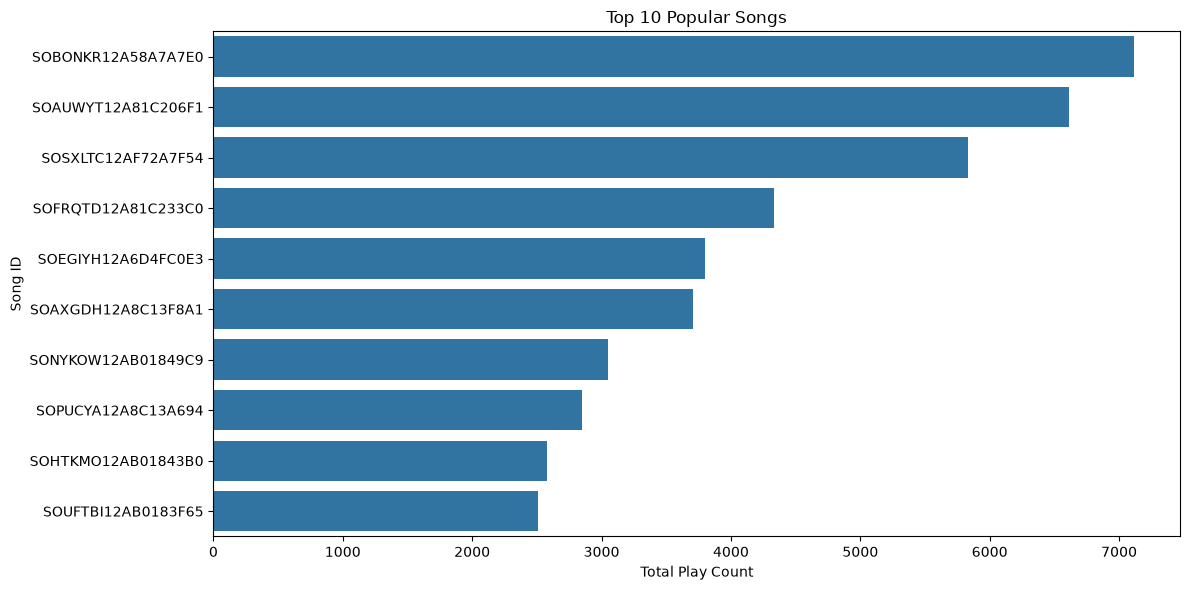

In [12]:
# ==========================================
# STEP 11.1: TOP 10 POPULAR SONGS
# ==========================================

top_songs = (
    df_clean.groupby("song_id")["play_count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_songs.columns = ["song_id", "total_plays"]

print("TOP 10 POPULAR SONGS")
display(top_songs)

# Visualize
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_songs,
    x="total_plays",
    y="song_id"
)

plt.title("Top 10 Popular Songs")
plt.xlabel("Total Play Count")
plt.ylabel("Song ID")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "top_10_songs.png")
plt.show()

TOP 10 MOST ACTIVE USERS


,user_id,total_plays
0,283882c3d18ff2ad0e17124002ec02b847d06e9a,3055
1,13ce57b3a25ef63fa614335fd838e8024c42ec17,2615
2,9acce6b22c8ae6adbd9e0933fb0a374b149e8e88,2562
3,4e11f45d732f4861772b2906f81a7d384552ad12,2478
4,6a944bfe30ae8d6b873139e8305ae131f1607d5f,2404
5,c0ff0f1c93f67c1fb372b36b1b08bb4c76bead7d,2361
6,7e40c676afe9ffcb80dfcb62e2acffd26ae21996,2347
7,371e9aff6b9f644e7598dbc4dd5640b1544b97f3,2330
8,da681f423e8574d2581534fd138eae264dea0f5c,2109
9,0d0f80a34807aab31a3521424d456d30bf2c93d9,2053


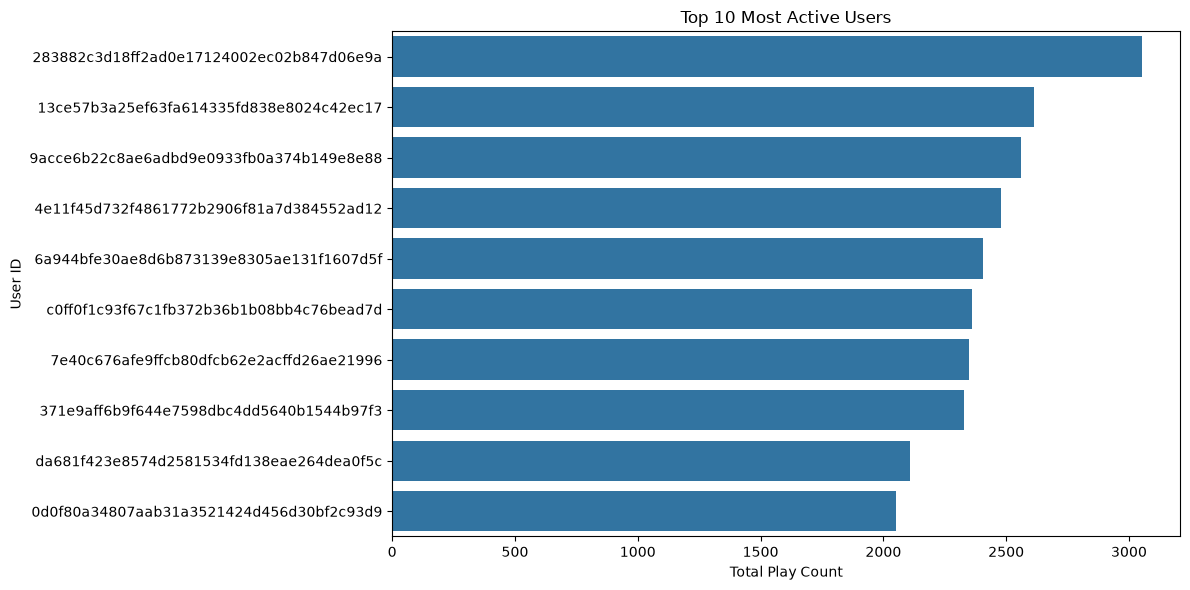

In [13]:
# ==========================================
# STEP 11.2: MOST ACTIVE USERS
# ==========================================

top_users = (
    df_clean.groupby("user_id")["play_count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_users.columns = ["user_id", "total_plays"]

print("TOP 10 MOST ACTIVE USERS")
display(top_users)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_users,
    x="total_plays",
    y="user_id"
)

plt.title("Top 10 Most Active Users")
plt.xlabel("Total Play Count")
plt.ylabel("User ID")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "top_10_users.png")
plt.show()

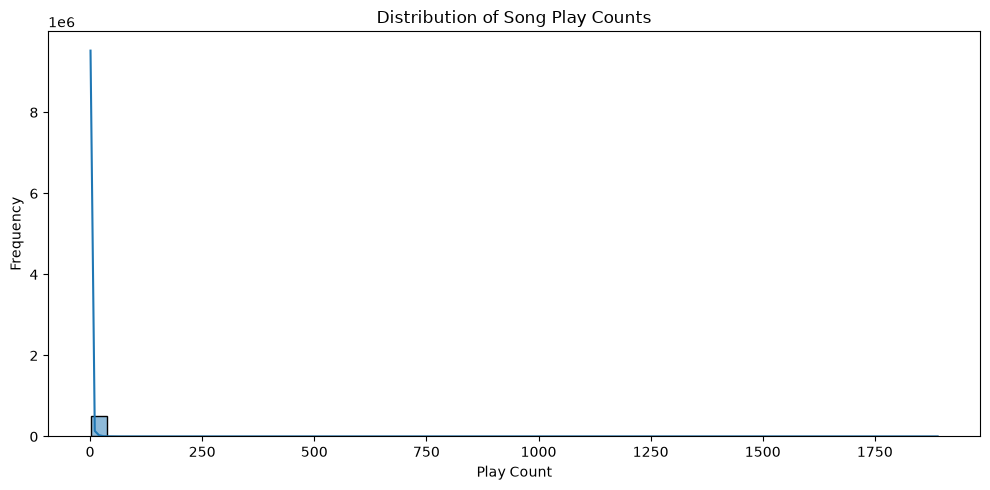

In [14]:
# ==========================================
# STEP 11.3: PLAY COUNT DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["play_count"],
    bins=50,
    kde=True
)

plt.title("Distribution of Song Play Counts")
plt.xlabel("Play Count")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "play_count_distribution.png")
plt.show()

In [15]:
# ==========================================
# STEP 11.4: EDA SUMMARY
# ==========================================

eda_summary = {
    "Total Interactions": len(df_clean),
    "Unique Users": df_clean["user_id"].nunique(),
    "Unique Songs": df_clean["song_id"].nunique(),
    "Average Play Count": df_clean["play_count"].mean(),
    "Median Play Count": df_clean["play_count"].median(),
    "Maximum Play Count": df_clean["play_count"].max()
}

for metric, value in eda_summary.items():
    print(f"{metric}: {value}")

print("\nEDA completed successfully!")

Total Interactions: 500000
Unique Users: 10354
Unique Songs: 108797
Average Play Count: 2.902846
Median Play Count: 1.0
Maximum Play Count: 1890

EDA completed successfully!


In [16]:
from scipy.sparse import csr_matrix, save_npz, load_npz

print("Sparse matrix libraries imported successfully!")


Sparse matrix libraries imported successfully!


In [17]:
# ==========================================
# STEP 12.2: USER-SONG INTERACTIONS
# ==========================================

interaction_df = (
    df_clean.groupby(["user_id", "song_id"], as_index=False)
    ["play_count"].sum()
)

print("Total interactions:", len(interaction_df))
print("Unique users:", interaction_df["user_id"].nunique())
print("Unique songs:", interaction_df["song_id"].nunique())

display(interaction_df.head())

Total interactions: 500000
Unique users: 10354
Unique songs: 108797


,user_id,song_id,play_count
0,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOBZZDU12A6310D8A3,1
1,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOCHADN12A6310ED94,1
2,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SODMFNK12AF72A2A27,1
3,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOFELBC12A58A7A5B3,1
4,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOMHLHX12A58A7AA5B,1


In [18]:
# ==========================================
# STEP 12.3: CREATE SPARSE MATRIX
# ==========================================

# Create numeric user and song indexes
user_codes, user_ids = pd.factorize(
    interaction_df["user_id"],
    sort=True
)

song_codes, song_ids = pd.factorize(
    interaction_df["song_id"],
    sort=True
)

# Matrix dimensions
n_users = len(user_ids)
n_songs = len(song_ids)

# Build sparse matrix
user_song_matrix = csr_matrix(
    (
        interaction_df["play_count"].to_numpy(dtype=np.float32),
        (user_codes, song_codes)
    ),
    shape=(n_users, n_songs),
    dtype=np.float32
)

print("User-Song Matrix Created!")
print("Matrix shape:", user_song_matrix.shape)
print("Users:", n_users)
print("Songs:", n_songs)
print("Non-zero interactions:", user_song_matrix.nnz)

User-Song Matrix Created!
Matrix shape: (10354, 108797)
Users: 10354
Songs: 108797
Non-zero interactions: 500000


In [19]:
# ==========================================
# STEP 12.4: MATRIX SPARSITY
# ==========================================

total_possible = n_users * n_songs

density = (
    user_song_matrix.nnz / total_possible
) * 100

sparsity = 100 - density

print("Matrix density:", round(density, 4), "%")
print("Matrix sparsity:", round(sparsity, 4), "%")

Matrix density: 0.0444 %
Matrix sparsity: 99.9556 %


In [20]:
# ==========================================
# STEP 12.5: SAVE MATRIX AND MAPPINGS
# ==========================================

save_npz(
    PROCESSED_DIR / "user_song_matrix.npz",
    user_song_matrix
)

pd.DataFrame({
    "user_index": np.arange(n_users),
    "user_id": user_ids.astype(str)
}).to_csv(
    PROCESSED_DIR / "user_index.csv",
    index=False
)

pd.DataFrame({
    "song_index": np.arange(n_songs),
    "song_id": song_ids.astype(str)
}).to_csv(
    PROCESSED_DIR / "song_index.csv",
    index=False
)

print("Matrix and mappings saved successfully!")

Matrix and mappings saved successfully!


In [21]:
# ==========================================
# STEP 13.1: TRAIN-TEST SPLIT
# ==========================================

import numpy as np
import pandas as pd

# Aggregate user-song interactions
interaction_df = (
    df_clean.groupby(
        ["user_id", "song_id"],
        as_index=False
    )
    .agg(play_count=("play_count", "sum"))
)

# Split each user's interactions separately
rng = np.random.default_rng(42)

train_parts = []
test_parts = []

for _, user_rows in interaction_df.groupby("user_id", sort=False):

    if len(user_rows) < 2:
        train_parts.append(user_rows)
        continue

    order = rng.permutation(len(user_rows))

    test_count = max(1, int(round(len(user_rows) * 0.20)))
    test_count = min(test_count, len(user_rows) - 1)

    test_parts.append(user_rows.iloc[order[:test_count]])
    train_parts.append(user_rows.iloc[order[test_count:]])

train_df = pd.concat(train_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Total records:", len(interaction_df))

print("Training percentage:",
      round(len(train_df) / len(interaction_df) * 100, 2))

print("Testing percentage:",
      round(len(test_df) / len(interaction_df) * 100, 2))

Training records: 400103
Testing records: 99897
Total records: 500000
Training percentage: 80.02
Testing percentage: 19.98


In [22]:
# ==========================================
# STEP 13.2: TRAINING SPARSE MATRIX
# ==========================================

from scipy.sparse import csr_matrix

# Create mappings using training data only
user_ids = pd.Index(
    train_df["user_id"].unique()
).sort_values()

song_ids = pd.Index(
    train_df["song_id"].unique()
).sort_values()

user_to_index = {
    user: idx for idx, user in enumerate(user_ids)
}

song_to_index = {
    song: idx for idx, song in enumerate(song_ids)
}

# Convert IDs into numeric indexes
user_idx = train_df["user_id"].map(user_to_index).to_numpy()
song_idx = train_df["song_id"].map(song_to_index).to_numpy()

# Log transformation reduces the effect of extremely high play counts
weights = np.log1p(
    train_df["play_count"].to_numpy(dtype=np.float32)
)

# Construct user-item matrix
train_user_song_matrix = csr_matrix(
    (weights, (user_idx, song_idx)),
    shape=(len(user_ids), len(song_ids)),
    dtype=np.float32
)

print("Training matrix:", train_user_song_matrix.shape)
print("Non-zero interactions:", train_user_song_matrix.nnz)

Training matrix: (10354, 97405)
Non-zero interactions: 400103


In [23]:
# ==========================================
# STEP 13.3: ALS MODEL TRAINING
# ==========================================

from implicit.als import AlternatingLeastSquares
import time

als_model = AlternatingLeastSquares(
    factors=32,
    regularization=0.1,
    alpha=20,
    iterations=10,
    random_state=42,
    num_threads=4
)

start_time = time.time()

als_model.fit(
    train_user_song_matrix,
    show_progress=True
)

training_time = time.time() - start_time

print("\nALS MODEL TRAINED SUCCESSFULLY!")
print("Training time:", round(training_time, 2), "seconds")
print("User factors:", als_model.user_factors.shape)
print("Song factors:", als_model.item_factors.shape)

E:\FDP_MLOPS\song_m1\.venv\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 12 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()
100%|██████████| 10/10 [00:04<00:00,  2.31it/s]


ALS MODEL TRAINED SUCCESSFULLY!
Training time: 4.4 seconds
User factors: (10354, 32)
Song factors: (97405, 32)


In [24]:
# ==========================================
# STEP 13.4: GENERATE RECOMMENDATIONS
# ==========================================

# Select one user from the training dataset
sample_user_index = 0

recommended_indices, recommendation_scores = als_model.recommend(
    userid=sample_user_index,
    user_items=train_user_song_matrix[sample_user_index],
    N=10,
    filter_already_liked_items=True
)

recommendations_df = pd.DataFrame({
    "song_id": [
        song_ids[int(idx)]
        for idx in recommended_indices
    ],
    "recommendation_score": recommendation_scores
})

print("Selected user:", user_ids[sample_user_index])
print("\nTOP 10 RECOMMENDED SONGS")

display(recommendations_df)

Selected user: 0007c0e74728ca9ef0fe4eb7f75732e8026a278b

TOP 10 RECOMMENDED SONGS


,song_id,recommendation_score
0,SOAMIQK12A6701D94F,0.163958
1,SOKKKZW12A6D4F7F88,0.154858
2,SOZYSDT12A8C13BFD7,0.151054
3,SOIOESO12A6D4F621D,0.143984
4,SOLWRZI12A6D4FC4F0,0.143254
5,SOAYATB12A6701FD50,0.142823
6,SOQGOPT12AAF3B2B27,0.141727
7,SOAIAAT12A8C145D49,0.133848
8,SOFTWWH12AB017AD0E,0.133187
9,SOXBCZH12A67ADAD77,0.131306


In [25]:
# ==========================================
# STEP 13.5: SAVE ALS MODEL
# ==========================================

als_model.save(
    str(MODEL_DIR / "als_collaborative_filtering.npz")
)

# Save training mappings
pd.DataFrame({
    "user_index": range(len(user_ids)),
    "user_id": user_ids.astype(str)
}).to_csv(
    PROCESSED_DIR / "user_index_train.csv",
    index=False
)

pd.DataFrame({
    "song_index": range(len(song_ids)),
    "song_id": song_ids.astype(str)
}).to_csv(
    PROCESSED_DIR / "song_index_train.csv",
    index=False
)

print("ALS model and mappings saved successfully!")

ALS model and mappings saved successfully!


In [26]:
# ==========================================
# STEP 16: ALS MODEL EVALUATION
# ==========================================

# Keep only test interactions whose users and songs
# are present in our training mappings.

test_known = test_df[
    test_df["user_id"].isin(user_to_index) &
    test_df["song_id"].isin(song_to_index)
].copy()

# Actual relevant songs for each test user
relevant_by_user = (
    test_known.groupby("user_id")["song_id"]
    .apply(set)
    .to_dict()
)

# Evaluation users
evaluation_users = list(relevant_by_user.keys())

# Use up to 1000 users for initial evaluation
rng = np.random.default_rng(42)

if len(evaluation_users) > 1000:
    evaluation_users = rng.choice(
        evaluation_users,
        size=1000,
        replace=False
    ).tolist()

K = 10

precision_values = []
recall_values = []
hit_values = []

for user_id in evaluation_users:

    user_idx = user_to_index[user_id]

    recommended_indices, scores = als_model.recommend(
        userid=user_idx,
        user_items=train_user_song_matrix[user_idx],
        N=K,
        filter_already_liked_items=True
    )

    recommended_songs = {
        song_ids[int(idx)]
        for idx in recommended_indices
    }

    actual_songs = relevant_by_user[user_id]

    hits = len(recommended_songs.intersection(actual_songs))

    precision_values.append(hits / K)
    recall_values.append(hits / len(actual_songs))
    hit_values.append(1 if hits > 0 else 0)


# Calculate final metrics
precision_at_10 = np.mean(precision_values)
recall_at_10 = np.mean(recall_values)
hit_rate_at_10 = np.mean(hit_values)

print("ALS MODEL EVALUATION RESULTS")
print("=" * 45)

print("Evaluated users:", len(evaluation_users))
print("Precision@10:", round(precision_at_10, 4))
print("Recall@10:", round(recall_at_10, 4))
print("Hit Rate@10:", round(hit_rate_at_10, 4))

ALS MODEL EVALUATION RESULTS
Evaluated users: 1000
Precision@10: 0.0418
Recall@10: 0.0633
Hit Rate@10: 0.295


In [27]:
evaluation_results = pd.DataFrame({
    "Metric": [
        "Precision@10",
        "Recall@10",
        "Hit Rate@10"
    ],
    "Score": [
        precision_at_10,
        recall_at_10,
        hit_rate_at_10
    ]
})

display(evaluation_results)

evaluation_results.to_csv(
    REPORT_DIR / "als_evaluation_results.csv",
    index=False
)

print("Evaluation report saved successfully!")

,Metric,Score
0,Precision@10,0.041800
1,Recall@10,0.063301
2,Hit Rate@10,0.295000


Evaluation report saved successfully!


In [28]:
# ==========================================
# STEP 17.1: CONNECT TO SONG METADATA DATABASE
# ==========================================

import sqlite3
import pandas as pd
from pathlib import Path

METADATA_FILE = RAW_DIR / "track_metadata.db"

# Connect to SQLite database
conn = sqlite3.connect(str(METADATA_FILE))

print("Database connected successfully!")

# Check database integrity
integrity = conn.execute(
    "PRAGMA integrity_check;"
).fetchone()[0]

print("Database integrity:", integrity)

# Find available tables
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table';
    """,
    conn
)

print("\nAvailable database tables:")
display(tables)

Database connected successfully!
Database integrity: ok

Available database tables:


,name
0,songs


In [29]:
# ==========================================
# STEP 17.2: INSPECT SONG METADATA
# ==========================================

schema = pd.read_sql_query(
    "PRAGMA table_info(songs);",
    conn
)

print("SONGS TABLE STRUCTURE")
display(schema)

# Display first five records
metadata_sample = pd.read_sql_query(
    "SELECT * FROM songs LIMIT 5;",
    conn
)

print("\nSAMPLE SONG METADATA")
display(metadata_sample)

SONGS TABLE STRUCTURE


,cid,name,type,notnull,dflt_value,pk
0,0,track_id,TEXT,0,None,1
1,1,title,TEXT,0,None,0
2,2,song_id,TEXT,0,None,0
3,3,release,TEXT,0,None,0
4,4,artist_id,TEXT,0,None,0
5,5,artist_mbid,TEXT,0,None,0
6,6,artist_name,TEXT,0,None,0
7,7,duration,REAL,0,None,0
8,8,artist_familiarity,REAL,0,None,0
9,9,artist_hotttnesss,REAL,0,None,0



SAMPLE SONG METADATA


,track_id,title,song_id,release,artist_id,artist_mbid,artist_name,duration,artist_familiarity,artist_hotttnesss,year,track_7digitalid,shs_perf,shs_work
0,TRMMMYQ128F932D901,Silent Night,SOQMMHC12AB0180CB8,Monster Ballads X-Mas,ARYZTJS1187B98C555,357ff05d-848a-44cf-b608-cb34b5701ae5,Faster Pussy cat,252.05506,0.649822,0.394032,2003,7032331,-1,0
1,TRMMMKD128F425225D,Tanssi vaan,SOVFVAK12A8C1350D9,Karkuteillä,ARMVN3U1187FB3A1EB,8d7ef530-a6fd-4f8f-b2e2-74aec765e0f9,Karkkiautomaatti,156.55138,0.439604,0.356992,1995,1514808,-1,0
2,TRMMMRX128F93187D9,No One Could Ever,SOGTUKN12AB017F4F1,Butter,ARGEKB01187FB50750,3d403d44-36ce-465c-ad43-ae877e65adc4,Hudson Mohawke,138.97098,0.643681,0.437504,2006,6945353,-1,0
3,TRMMMCH128F425532C,Si Vos Querés,SOBNYVR12A8C13558C,De Culo,ARNWYLR1187B9B2F9C,12be7648-7094-495f-90e6-df4189d68615,Yerba Brava,145.05751,0.448501,0.372349,2003,2168257,-1,0
4,TRMMMWA128F426B589,Tangle Of Aspens,SOHSBXH12A8C13B0DF,Rene Ablaze Presents Winter Sessions,AREQDTE1269FB37231,,Der Mystic,514.29832,0.000000,0.000000,0,2264873,-1,0


In [30]:
total_tracks = pd.read_sql_query(
    "SELECT COUNT(*) AS total_tracks FROM songs;",
    conn
)

print("Total tracks in metadata database:")
display(total_tracks)

Total tracks in metadata database:


,total_tracks
0,1000000


In [31]:
# ==========================================
# STEP 18.1: PREPARE SONG IDS
# ==========================================

interaction_df = (
    df_clean.groupby(
        ["user_id", "song_id"],
        as_index=False
    )
    .agg(play_count=("play_count", "sum"))
)

song_id_list = (
    df_clean["song_id"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

print("Total user-song interactions:", len(interaction_df))
print("Unique songs in sample:", len(song_id_list))

Total user-song interactions: 500000
Unique songs in sample: 108797


In [32]:
# ==========================================
# STEP 18.2: MATCH SONG METADATA
# ==========================================

# Create a temporary SQLite table
conn.execute("DROP TABLE IF EXISTS sample_song_ids")

conn.execute("""
    CREATE TEMP TABLE sample_song_ids (
        song_id TEXT PRIMARY KEY
    )
""")

# Insert song IDs
conn.executemany(
    "INSERT OR IGNORE INTO sample_song_ids (song_id) VALUES (?)",
    ((song_id,) for song_id in song_id_list)
)

conn.commit()

# Retrieve matching metadata
metadata_df = pd.read_sql_query("""
    SELECT
        s.song_id,
        s.title,
        s.artist_name,
        s.release,
        s.duration,
        s.artist_familiarity,
        s.artist_hotttnesss,
        s.year
    FROM songs s
    INNER JOIN sample_song_ids x
        ON s.song_id = x.song_id
""", conn)

# Keep one metadata record per song ID
metadata_df = (
    metadata_df
    .drop_duplicates(subset=["song_id"])
    .reset_index(drop=True)
)

print("Metadata retrieved successfully!")
print("Matched songs:", len(metadata_df))

display(metadata_df.head(10))

Metadata retrieved successfully!
Matched songs: 108797


,song_id,title,artist_name,release,duration,artist_familiarity,artist_hotttnesss,year
0,SOSDCFG12AB0184647,006,Lena Philipsson,Lena 20 År,262.26893,0.529819,0.410229,1998
1,SOIMMJJ12AF72AD643,Rock-N-Rule,Emery,I'm Only A Man (Bonus Track Version),217.57342,0.738996,0.563367,2007
2,SOGNNYL12A6D4F910B,Raspberry Beret (LP Version),Prince & The Revolution,The Hits/The B-Sides,212.06159,0.684808,0.485445,0
3,SODDEQU12AAF3B2FC8,Passione,Neffa,Alla Fine Della Notte,228.44036,0.530647,0.381921,2007
4,SOWWQXA12A81C1F9CA,Scream,Billy Idol,Devil's Playground,282.93179,0.820222,0.485105,2005
5,SOFSJXP12AB017E676,I Just Want To Be With You This Christmas,Katie Armiger,My Christmas,200.09751,0.595414,0.417099,0
6,SOSNKHA12AB0185BD6,Redemption,Write This Down,Write This Down,192.49587,0.651981,0.441647,2010
7,SOUIUYF12AC3DF998F,Two Legged Sheep,Kingdom Come,Ain't Crying for the Moon,329.40363,0.613547,0.410692,2006
8,SOHNWIM12A67ADF7D9,Get Along (Feat: Pace Won) (Instrumental),Morcheeba,Charango,227.47383,0.819087,0.533117,2002
9,SOAAQWU12A8C13F908,Just Is,Lamb,What Sound,678.89587,0.732409,0.507957,0


In [33]:
# ==========================================
# STEP 18.3: MERGE INTERACTIONS AND METADATA
# ==========================================

interactions_with_metadata = interaction_df.merge(
    metadata_df,
    on="song_id",
    how="left",
    indicator=True
)

matched = (
    interactions_with_metadata["_merge"] == "both"
).sum()

total = len(interactions_with_metadata)

coverage = (matched / total) * 100 if total else 0

print("METADATA INTEGRATION RESULTS")
print("-" * 40)

print("Total interactions:", total)
print("Matched interactions:", matched)
print("Unmatched interactions:", total - matched)
print("Metadata coverage:", round(coverage, 2), "%")

display(
    interactions_with_metadata[
        [
            "user_id",
            "song_id",
            "play_count",
            "title",
            "artist_name",
            "year"
        ]
    ].head(10)
)

METADATA INTEGRATION RESULTS
----------------------------------------
Total interactions: 500000
Matched interactions: 500000
Unmatched interactions: 0
Metadata coverage: 100.0 %


,user_id,song_id,play_count,title,artist_name,year
0,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOBZZDU12A6310D8A3,1,Don't Dream It's Over,Crowded House,1986
1,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOCHADN12A6310ED94,1,Move The Crowd,Eric B. & Rakim,1987
2,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SODMFNK12AF72A2A27,1,The Great Pretender (Original Single Version) ...,Freddie Mercury,0
3,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOFELBC12A58A7A5B3,1,Thank U (Album Version),Alanis Morissette,1998
4,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOMHLHX12A58A7AA5B,1,You Learn (Album Version),Alanis Morissette,1996
5,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOMWXVR12A6D4F7B9D,1,Into Temptation,Crowded House,1988
6,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOPWZGK12A67020744,1,Ironic (Acoustic Album Version),Alanis Morissette,2007
7,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOQNLIG12A6D4F937D,1,Head Over Feet (Album Version),Alanis Morissette,1995
8,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOTSXKF12A6701C3AF,2,That I Would Be Good (Live/Unplugged Version),Alanis Morissette,0
9,0007c0e74728ca9ef0fe4eb7f75732e8026a278b,SOWKRRE12A6702073E,1,Hand In My Pocket (Acoustic Album Version),Alanis Morissette,2005


In [34]:
# ==========================================
# STEP 19.1: PREPARE CONTENT FEATURES
# ==========================================

content_df = metadata_df.copy()

# Select useful metadata columns
content_columns = [
    "song_id",
    "title",
    "artist_name",
    "release"
]

content_df = content_df[content_columns].copy()

# Handle missing values
for col in ["title", "artist_name", "release"]:
    content_df[col] = (
        content_df[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

# Remove duplicate song records
content_df = content_df.drop_duplicates(
    subset=["song_id"]
)

# Create combined text
content_df["content_text"] = (
    content_df["title"] + " " +
    content_df["artist_name"] + " " +
    content_df["release"]
)

# Remove empty descriptions
content_df = content_df[
    content_df["content_text"].str.strip() != ""
].reset_index(drop=True)

print("CONTENT DATA PREPARED")
print("-" * 40)

print("Total songs:", len(content_df))
print("Missing song IDs:", content_df["song_id"].isnull().sum())

display(content_df.head(10))

CONTENT DATA PREPARED
----------------------------------------
Total songs: 108797
Missing song IDs: 0


,song_id,title,artist_name,release,content_text
0,SOSDCFG12AB0184647,006,Lena Philipsson,Lena 20 År,006 Lena Philipsson Lena 20 År
1,SOIMMJJ12AF72AD643,Rock-N-Rule,Emery,I'm Only A Man (Bonus Track Version),Rock-N-Rule Emery I'm Only A Man (Bonus Track ...
2,SOGNNYL12A6D4F910B,Raspberry Beret (LP Version),Prince & The Revolution,The Hits/The B-Sides,Raspberry Beret (LP Version) Prince & The Revo...
3,SODDEQU12AAF3B2FC8,Passione,Neffa,Alla Fine Della Notte,Passione Neffa Alla Fine Della Notte
4,SOWWQXA12A81C1F9CA,Scream,Billy Idol,Devil's Playground,Scream Billy Idol Devil's Playground
5,SOFSJXP12AB017E676,I Just Want To Be With You This Christmas,Katie Armiger,My Christmas,I Just Want To Be With You This Christmas Kati...
6,SOSNKHA12AB0185BD6,Redemption,Write This Down,Write This Down,Redemption Write This Down Write This Down
7,SOUIUYF12AC3DF998F,Two Legged Sheep,Kingdom Come,Ain't Crying for the Moon,Two Legged Sheep Kingdom Come Ain't Crying for...
8,SOHNWIM12A67ADF7D9,Get Along (Feat: Pace Won) (Instrumental),Morcheeba,Charango,Get Along (Feat: Pace Won) (Instrumental) Morc...
9,SOAAQWU12A8C13F908,Just Is,Lamb,What Sound,Just Is Lamb What Sound


In [35]:
# ==========================================
# STEP 19.2: TF-IDF VECTORIZATION
# ==========================================

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    content_df["content_text"]
)

print("TF-IDF CREATED SUCCESSFULLY!")
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Vocabulary Size:", len(tfidf_vectorizer.vocabulary_))
print("Non-zero Features:", tfidf_matrix.nnz)

TF-IDF CREATED SUCCESSFULLY!
TF-IDF Matrix Shape: (108797, 50000)
Vocabulary Size: 50000
Non-zero Features: 864509


In [36]:
# ==========================================
# STEP 19.3: CONTENT-BASED RECOMMENDATIONS
# ==========================================

from sklearn.metrics.pairwise import linear_kernel

# Build song ID to matrix row mapping
song_to_row = {
    song_id: idx
    for idx, song_id in enumerate(content_df["song_id"])
}

# Find a popular song that has metadata
popular_song_ids = (
    interaction_df.groupby("song_id")["play_count"]
    .sum()
    .sort_values(ascending=False)
    .index
)

seed_song_id = next(
    (
        song_id for song_id in popular_song_ids
        if song_id in song_to_row
    ),
    None
)

assert seed_song_id is not None, "No matching song found!"

seed_index = song_to_row[seed_song_id]

print("SELECTED SONG")
display(
    content_df.iloc[[seed_index]][
        ["song_id", "title", "artist_name", "release"]
    ]
)

# Calculate similarity against all songs
similarity_scores = linear_kernel(
    tfidf_matrix[seed_index],
    tfidf_matrix
).flatten()

# Exclude the selected song itself
similarity_scores[seed_index] = -1

# Retrieve top 10 similar songs
top_indices = np.argsort(similarity_scores)[::-1][:10]

content_recommendations = content_df.iloc[
    top_indices
][["song_id", "title", "artist_name", "release"]].copy()

content_recommendations["similarity_score"] = (
    similarity_scores[top_indices]
)

print("TOP 10 CONTENT-BASED RECOMMENDATIONS")
display(content_recommendations)

SELECTED SONG


,song_id,title,artist_name,release
49087,SOBONKR12A58A7A7E0,You're The One,Dwight Yoakam,If There Was A Way


TOP 10 CONTENT-BASED RECOMMENDATIONS


,song_id,title,artist_name,release,similarity_score
24580,SOAIAOV12AC9072FC3,Since I Started Drinkin' Again,Dwight Yoakam,If There Was A Way,0.803083
92987,SOSJAKQ12AB017E976,Nothing (LP Version),Dwight Yoakam,Last Chance For A Thousand Years - Dwight Yoak...,0.764302
98537,SOOWYLL12AB017DAC4,Cattle Call,Dwight Yoakam,The Horse Whisperer,0.749277
4540,SOGDPDR12A8C14481F,Listen (LP Version),Dwight Yoakam,A Long Way Home,0.643774
76567,SOJEXKY12A8C1447CE,That's Okay (LP Version),Dwight Yoakam,A Long Way Home,0.633308
21440,SOGZWMJ12AC9097245,Near You (LP Version),Dwight Yoakam,Gone,0.608992
84967,SOMOJIB12A8C142E08,Traveler's Lantern (LP Version),Dwight Yoakam,A Long Way Home,0.596841
70561,SOHNNZR12AC9097205,Baby Why Not (LP Version),Dwight Yoakam,Gone,0.585971
25303,SOGNREW12AC90971F6,This Much I Know (LP Version),Dwight Yoakam,Gone,0.584640
53734,SOKJXUN12AC9097213,One More Night (LP Version),Dwight Yoakam,Gone,0.583163


In [37]:
# ==========================================
# STEP 19.4: SAVE CONTENT MODEL
# ==========================================

import joblib
from scipy.sparse import save_npz

# Save TF-IDF vectorizer
joblib.dump(
    tfidf_vectorizer,
    MODEL_DIR / "tfidf_vectorizer.joblib"
)

# Save feature matrix
save_npz(
    MODEL_DIR / "song_tfidf_matrix.npz",
    tfidf_matrix
)

# Save content recommendations
content_recommendations.to_csv(
    REPORT_DIR / "content_recommendations.csv",
    index=False
)

# Save song mapping
content_df.to_csv(
    PROCESSED_DIR / "content_song_metadata.csv",
    index=False
)

print("CONTENT-BASED MODEL SAVED SUCCESSFULLY!")

CONTENT-BASED MODEL SAVED SUCCESSFULLY!


In [38]:
# ==========================================
# STEP 20.1: HYBRID RECOMMENDATION SYSTEM
# ==========================================

from sklearn.metrics.pairwise import linear_kernel
from scipy.sparse import csr_matrix
import numpy as np
import pandas as pd

# Create consistent song ID mappings
content_song_ids = content_df["song_id"].astype(str).tolist()

content_song_to_row = {
    song_id: idx
    for idx, song_id in enumerate(content_song_ids)
}

train_song_ids = [
    str(song_id) for song_id in song_ids
]

# Hybrid recommendation function
def recommend_hybrid(
    user_id,
    top_n=10,
    candidate_n=100,
    als_weight=0.60,
    content_weight=0.40
):

    user_id = str(user_id)

    if user_id not in user_to_index:
        raise ValueError("User not found in training data.")

    user_idx = user_to_index[user_id]

    # 1. Get user's training history
    user_history = train_df[
        train_df["user_id"].astype(str) == user_id
    ].copy()

    seen_song_ids = set(
        user_history["song_id"].astype(str)
    )

    # 2. ALS recommendations
    als_indices, als_scores = als_model.recommend(
        userid=user_idx,
        user_items=train_user_song_matrix[user_idx],
        N=candidate_n,
        filter_already_liked_items=True
    )

    als_rank = {
        train_song_ids[int(idx)]: rank + 1
        for rank, idx in enumerate(als_indices)
    }

    # 3. Build user's content profile
    history_rows = []
    history_weights = []

    for row in user_history.itertuples(index=False):

        sid = str(row.song_id)

        if sid in content_song_to_row:
            history_rows.append(content_song_to_row[sid])
            history_weights.append(
                np.log1p(float(row.play_count))
            )

    content_rank = {}

    if history_rows:

        user_song_features = tfidf_matrix[history_rows]

        weighted_features = user_song_features.multiply(
            np.array(history_weights)[:, None]
        )

        user_profile = csr_matrix(
            np.asarray(weighted_features.sum(axis=0))
        )

        # 4. Calculate content similarity
        content_scores = linear_kernel(
            user_profile,
            tfidf_matrix
        ).ravel()

        # Exclude previously listened songs
        for idx, sid in enumerate(content_song_ids):
            if sid in seen_song_ids:
                content_scores[idx] = -np.inf

        top_content_indices = np.argsort(
            content_scores
        )[::-1][:candidate_n]

        content_rank = {
            content_song_ids[int(idx)]: rank + 1
            for rank, idx in enumerate(top_content_indices)
        }

    # 5. Combine both rankings using RRF
    candidate_ids = set(als_rank) | set(content_rank)

    hybrid_rows = []

    for sid in candidate_ids:

        score = 0.0

        if sid in als_rank:
            score += als_weight / (60 + als_rank[sid])

        if sid in content_rank:
            score += content_weight / (60 + content_rank[sid])

        hybrid_rows.append({
            "song_id": sid,
            "als_rank": als_rank.get(sid),
            "content_rank": content_rank.get(sid),
            "hybrid_score": score
        })

    result = pd.DataFrame(hybrid_rows)

    result = result.sort_values(
        "hybrid_score",
        ascending=False
    ).head(top_n).reset_index(drop=True)

    # 6. Attach readable song metadata
    display_metadata = (
        content_df[
            ["song_id", "title", "artist_name", "release"]
        ]
        .copy()
        .assign(song_id=lambda x: x["song_id"].astype(str))
        .drop_duplicates("song_id")
    )

    result = result.merge(
        display_metadata,
        on="song_id",
        how="left"
    )

    return result

In [39]:
# ==========================================
# STEP 20.2: GENERATE HYBRID RECOMMENDATIONS
# ==========================================

# Select the first training user
sample_user_id = str(user_ids[0])

hybrid_recommendations = recommend_hybrid(
    user_id=sample_user_id,
    top_n=10,
    candidate_n=100,
    als_weight=0.60,
    content_weight=0.40
)

print("HYBRID SONG RECOMMENDATION SYSTEM")
print("=" * 50)

print("Selected User:", sample_user_id)

display(hybrid_recommendations)

HYBRID SONG RECOMMENDATION SYSTEM
Selected User: 0007c0e74728ca9ef0fe4eb7f75732e8026a278b


,song_id,als_rank,content_rank,hybrid_score,title,artist_name,release
0,SOUSQYR12A6D4F74C1,24.0,5.0,0.013297,Thank You (Album Version),Alanis Morissette,The Collection
1,SOAMIQK12A6701D94F,1.0,NaN,0.009836,Don't Cry (Original),Guns N' Roses,Greatest Hits
2,SOKKKZW12A6D4F7F88,2.0,NaN,0.009677,Have You Ever Seen The Rain,Creedence Clearwater Revival,Chronicle: 20 Greatest Hits
3,SOZYSDT12A8C13BFD7,3.0,NaN,0.009524,Under Pressure,Queen,Queen On Fire - Live At The Bowl
4,SOIOESO12A6D4F621D,4.0,NaN,0.009375,Unwell (Album Version),matchbox twenty,More Than You Think You Are
5,SOBZZDU12A6310D8A3,63.0,30.0,0.009322,Don't Dream It's Over,Crowded House,Recurring Dream_ Best Of Crowded House (Domest...
6,SOLWRZI12A6D4FC4F0,5.0,NaN,0.009231,Fortunate Son,Creedence Clearwater Revival,More Creedence Gold
7,SOAYATB12A6701FD50,6.0,NaN,0.009091,Breakfast At Tiffany's,Deep Blue Something,Home
8,SOQGOPT12AAF3B2B27,7.0,NaN,0.008955,Wild World,Cat Stevens,Tea For The Tillerman
9,SOAIAAT12A8C145D49,8.0,NaN,0.008824,Bad Moon Rising,Creedence Clearwater Revival,The Complete Collection (Digital Box)


In [40]:
# ==========================================
# STEP 20.3: SAVE HYBRID RECOMMENDATIONS
# ==========================================

hybrid_recommendations.to_csv(
    REPORT_DIR / "hybrid_recommendations.csv",
    index=False
)

print("Hybrid recommendations saved successfully!")

print(
    "File:",
    REPORT_DIR / "hybrid_recommendations.csv"
)

Hybrid recommendations saved successfully!
File: E:\FDP_MLOPS\song_m1\reports\hybrid_recommendations.csv


In [41]:
# ==========================================
# STEP 20.4: MODEL COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Recommendation Model": [
        "Collaborative Filtering (ALS)",
        "Content-Based Filtering (TF-IDF)",
        "Hybrid Recommendation"
    ],
    "Method": [
        "User listening behaviour",
        "Song content similarity",
        "Combined ranking"
    ]
})

display(comparison)

,Recommendation Model,Method
0,Collaborative Filtering (ALS),User listening behaviour
1,Content-Based Filtering (TF-IDF),Song content similarity
2,Hybrid Recommendation,Combined ranking


In [42]:
# ==========================================
# STEP 21.1: PREPARE MODEL EVALUATION
# ==========================================

K = 10

# Common song catalogue supported by both models
content_catalog = set(
    content_df["song_id"].astype(str)
)

training_catalog = set(
    str(song_id) for song_id in song_ids
)

common_catalog = content_catalog & training_catalog

# Keep test songs available in the common catalogue
test_eval = test_df[
    test_df["user_id"].astype(str).isin(
        set(user_to_index.keys())
    ) &
    test_df["song_id"].astype(str).isin(common_catalog)
].copy()

relevant_by_user = (
    test_eval.groupby("user_id")["song_id"]
    .apply(lambda x: set(x.astype(str)))
    .to_dict()
)

evaluation_users = list(relevant_by_user.keys())

# Use 100 users for the initial comparison
rng = np.random.default_rng(42)

if len(evaluation_users) > 100:
    evaluation_users = rng.choice(
        evaluation_users,
        100,
        replace=False
    ).tolist()

evaluation_users = [str(u) for u in evaluation_users]

print("Evaluation users:", len(evaluation_users))
print("Common song catalogue:", len(common_catalog))
print("Evaluation preparation completed!")

Evaluation users: 100
Common song catalogue: 97405
Evaluation preparation completed!


In [43]:
# ==========================================
# STEP 21.2: MODEL RECOMMENDATION FUNCTIONS
# ==========================================

from sklearn.metrics.pairwise import linear_kernel

content_row_map = {
    str(song_id): idx
    for idx, song_id in enumerate(content_df["song_id"])
}

def get_als_recommendations(user_id, top_n=10):

    user_idx = user_to_index[user_id]

    indices, scores = als_model.recommend(
        userid=user_idx,
        user_items=train_user_song_matrix[user_idx],
        N=min(200, train_user_song_matrix.shape[1]),
        filter_already_liked_items=True
    )

    results = []

    for idx in indices:
        sid = str(song_ids[int(idx)])

        if sid in common_catalog:
            results.append(sid)

        if len(results) == top_n:
            break

    return results


def get_content_recommendations(user_id, top_n=10):

    history = train_df[
        train_df["user_id"].astype(str) == user_id
    ]

    rows = []
    weights = []

    for record in history.itertuples(index=False):

        sid = str(record.song_id)

        if sid in content_row_map:
            rows.append(content_row_map[sid])
            weights.append(np.log1p(float(record.play_count)))

    if not rows:
        return []

    profile = tfidf_matrix[rows].multiply(
        np.asarray(weights)[:, None]
    ).sum(axis=0)

    profile = csr_matrix(np.asarray(profile))

    scores = linear_kernel(
        profile,
        tfidf_matrix
    ).ravel()

    seen = set(history["song_id"].astype(str))

    for sid in seen:
        if sid in content_row_map:
            scores[content_row_map[sid]] = -np.inf

    ranked_indices = np.argsort(scores)[::-1]

    results = []

    for idx in ranked_indices:

        sid = str(content_df.iloc[idx]["song_id"])

        if sid in common_catalog and sid not in seen:
            results.append(sid)

        if len(results) == top_n:
            break

    return results

In [44]:
# ==========================================
# STEP 21.3: MODEL PERFORMANCE COMPARISON
# ==========================================

model_predictions = {
    "ALS": [],
    "Content-Based": [],
    "Hybrid": []
}

for user_id in evaluation_users:

    actual = relevant_by_user[user_id]

    # ALS recommendations
    als_recs = get_als_recommendations(user_id, K)

    # Content-based recommendations
    content_recs = get_content_recommendations(user_id, K)

    # Hybrid recommendations
    hybrid_df = recommend_hybrid(
        user_id=user_id,
        top_n=100,
        candidate_n=200,
        als_weight=0.60,
        content_weight=0.40
    )

    hybrid_recs = [
        str(sid)
        for sid in hybrid_df["song_id"]
        if str(sid) in common_catalog
    ][:K]

    for name, recs in [
        ("ALS", als_recs),
        ("Content-Based", content_recs),
        ("Hybrid", hybrid_recs)
    ]:

        hits = len(set(recs) & actual)

        precision = hits / K
        recall = hits / len(actual) if actual else 0
        hit_rate = 1 if hits > 0 else 0

        model_predictions[name].append({
            "precision": precision,
            "recall": recall,
            "hit_rate": hit_rate
        })


# Calculate average scores
comparison_results = []

for model_name, metrics in model_predictions.items():

    comparison_results.append({
        "Model": model_name,
        "Precision@10": np.mean(
            [m["precision"] for m in metrics]
        ),
        "Recall@10": np.mean(
            [m["recall"] for m in metrics]
        ),
        "Hit Rate@10": np.mean(
            [m["hit_rate"] for m in metrics]
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print("FINAL MODEL COMPARISON")
print("=" * 65)

display(comparison_df.round(4))

FINAL MODEL COMPARISON


,Model,Precision@10,Recall@10,Hit Rate@10
0,ALS,0.064,0.0941,0.41
1,Content-Based,0.092,0.1105,0.43
2,Hybrid,0.084,0.1277,0.51


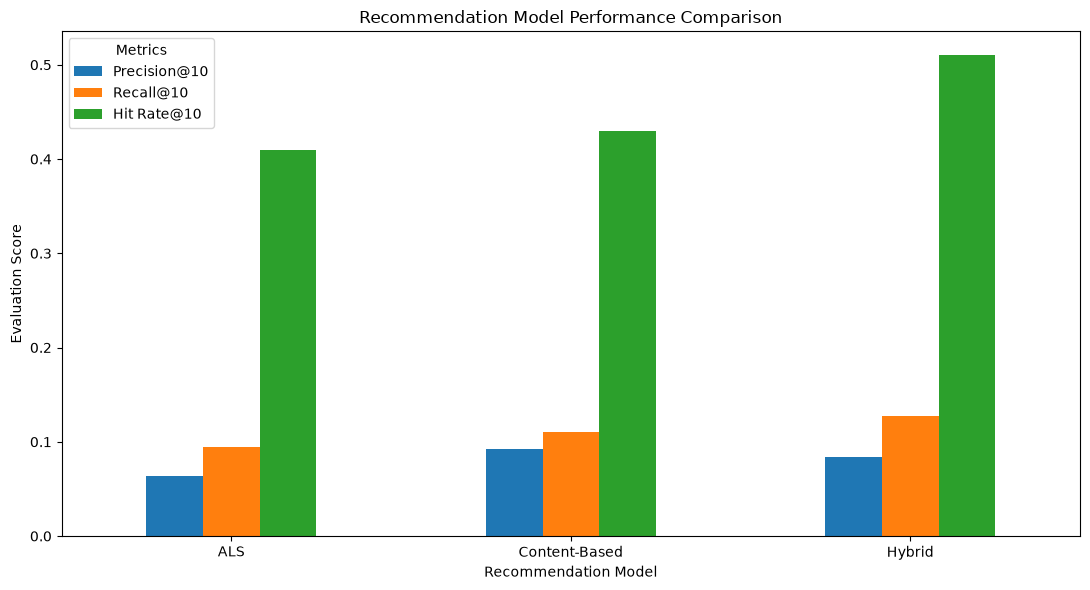

In [45]:
# ==========================================
# STEP 21.4: MODEL COMPARISON GRAPH
# ==========================================

comparison_plot = comparison_df.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Recommendation Model Performance Comparison")
plt.xlabel("Recommendation Model")
plt.ylabel("Evaluation Score")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "model_comparison.png"
)

plt.show()

In [46]:
comparison_df.to_csv(
    REPORT_DIR / "model_comparison_metrics.csv",
    index=False
)

print("Model comparison report saved!")
print("Location:", REPORT_DIR)

Model comparison report saved!
Location: E:\FDP_MLOPS\song_m1\reports


In [47]:
# ==========================================
# STEP 22.1: VALIDATION DATASET
# ==========================================

rng = np.random.default_rng(42)

tune_train_parts = []
validation_parts = []

for _, user_rows in train_df.groupby("user_id", sort=False):

    if len(user_rows) < 2:
        tune_train_parts.append(user_rows)
        continue

    indices = rng.permutation(len(user_rows))

    n_validation = max(1, int(len(user_rows) * 0.20))
    n_validation = min(n_validation, len(user_rows) - 1)

    validation_parts.append(
        user_rows.iloc[indices[:n_validation]]
    )

    tune_train_parts.append(
        user_rows.iloc[indices[n_validation:]]
    )

tune_train_df = pd.concat(
    tune_train_parts
).reset_index(drop=True)

validation_df = pd.concat(
    validation_parts
).reset_index(drop=True)

print("Tuning training records:", len(tune_train_df))
print("Validation records:", len(validation_df))
print("Final test records reserved:", len(test_df))

Tuning training records: 324262
Validation records: 75841
Final test records reserved: 99897


In [48]:
# ==========================================
# STEP 22.2: TUNING MATRIX
# ==========================================

from scipy.sparse import csr_matrix

tune_user_ids = pd.Index(
    tune_train_df["user_id"].unique()
).sort_values()

tune_song_ids = pd.Index(
    tune_train_df["song_id"].unique()
).sort_values()

tune_user_map = {
    user: idx for idx, user in enumerate(tune_user_ids)
}

tune_song_map = {
    song: idx for idx, song in enumerate(tune_song_ids)
}

user_idx = tune_train_df["user_id"].map(
    tune_user_map
).to_numpy()

song_idx = tune_train_df["song_id"].map(
    tune_song_map
).to_numpy()

weights = np.log1p(
    tune_train_df["play_count"].to_numpy(dtype=np.float32)
)

tune_matrix = csr_matrix(
    (weights, (user_idx, song_idx)),
    shape=(len(tune_user_ids), len(tune_song_ids)),
    dtype=np.float32
)

# Validation ground truth
validation_known = validation_df[
    validation_df["user_id"].isin(tune_user_map) &
    validation_df["song_id"].isin(tune_song_map)
]

validation_relevant = (
    validation_known.groupby("user_id")["song_id"]
    .apply(set)
    .to_dict()
)

print("Tuning matrix:", tune_matrix.shape)
print("Validation users:", len(validation_relevant))
print("Non-zero interactions:", tune_matrix.nnz)

Tuning matrix: (10354, 87491)
Validation users: 10135
Non-zero interactions: 324262


In [49]:
# ==========================================
# STEP 22.3: ALS HYPERPARAMETER TUNING
# ==========================================

from implicit.als import AlternatingLeastSquares
import time

configs = [
    {"factors": 32, "regularization": 0.1, "alpha": 20, "iterations": 10},
    {"factors": 64, "regularization": 0.1, "alpha": 20, "iterations": 15},
    {"factors": 32, "regularization": 0.05, "alpha": 10, "iterations": 15},
    {"factors": 64, "regularization": 0.05, "alpha": 20, "iterations": 10}
]

validation_users = list(validation_relevant.keys())

rng = np.random.default_rng(42)

if len(validation_users) > 100:
    validation_users = rng.choice(
        validation_users,
        size=100,
        replace=False
    ).tolist()

tuning_results = []

for config_number, config in enumerate(configs, start=1):

    print(f"\nTraining configuration {config_number}: {config}")

    model = AlternatingLeastSquares(
        factors=config["factors"],
        regularization=config["regularization"],
        alpha=config["alpha"],
        iterations=config["iterations"],
        random_state=42,
        num_threads=4
    )

    start = time.time()

    model.fit(tune_matrix, show_progress=False)

    training_seconds = time.time() - start

    precision_scores = []
    recall_scores = []
    hit_scores = []

    for user_id in validation_users:

        idx = tune_user_map[user_id]

        recommended_indices, _ = model.recommend(
            userid=idx,
            user_items=tune_matrix[idx],
            N=10,
            filter_already_liked_items=True
        )

        recommended = {
            tune_song_ids[int(i)]
            for i in recommended_indices
        }

        actual = validation_relevant[user_id]

        hits = len(recommended.intersection(actual))

        precision_scores.append(hits / 10)
        recall_scores.append(
            hits / len(actual) if actual else 0
        )
        hit_scores.append(1 if hits > 0 else 0)

    tuning_results.append({
        **config,
        "Precision@10": np.mean(precision_scores),
        "Recall@10": np.mean(recall_scores),
        "Hit Rate@10": np.mean(hit_scores),
        "Training Time": round(training_seconds, 2)
    })

    print("Configuration completed!")


Training configuration 1: {'factors': 32, 'regularization': 0.1, 'alpha': 20, 'iterations': 10}
Configuration completed!

Training configuration 2: {'factors': 64, 'regularization': 0.1, 'alpha': 20, 'iterations': 15}
Configuration completed!

Training configuration 3: {'factors': 32, 'regularization': 0.05, 'alpha': 10, 'iterations': 15}
Configuration completed!

Training configuration 4: {'factors': 64, 'regularization': 0.05, 'alpha': 20, 'iterations': 10}
Configuration completed!


In [50]:
# ==========================================
# STEP 22.4: SELECT BEST CONFIGURATION
# ==========================================

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by=["Recall@10", "Precision@10", "Hit Rate@10"],
    ascending=False
).reset_index(drop=True)

print("ALS HYPERPARAMETER COMPARISON")

display(tuning_df.round(4))

best_config = tuning_df.iloc[0]

print("\nBEST ALS CONFIGURATION")
print(best_config)

ALS HYPERPARAMETER COMPARISON


,factors,regularization,alpha,iterations,Precision@10,Recall@10,Hit Rate@10,Training Time
0,64,0.10,20,15,0.023,0.0575,0.20,5.86
1,32,0.05,10,15,0.022,0.0533,0.18,5.08
2,64,0.05,20,10,0.021,0.0513,0.18,4.50
3,32,0.10,20,10,0.020,0.0434,0.16,3.30



BEST ALS CONFIGURATION
factors           64.000000
regularization     0.100000
alpha             20.000000
iterations        15.000000
Precision@10       0.023000
Recall@10          0.057458
Hit Rate@10        0.200000
Training Time      5.860000
Name: 0, dtype: float64


In [51]:
# ==========================================
# STEP 22.5: FINAL OPTIMIZED ALS MODEL
# ==========================================

optimized_als_model = AlternatingLeastSquares(
    factors=int(best_config["factors"]),
    regularization=float(best_config["regularization"]),
    alpha=float(best_config["alpha"]),
    iterations=int(best_config["iterations"]),
    random_state=42,
    num_threads=4
)

optimized_als_model.fit(
    train_user_song_matrix,
    show_progress=True
)

# Save optimized model
optimized_als_model.save(
    str(MODEL_DIR / "als_collaborative_filtering_tuned.npz")
)

print("OPTIMIZED ALS MODEL TRAINED AND SAVED!")

100%|██████████| 15/15 [00:06<00:00,  2.26it/s]

OPTIMIZED ALS MODEL TRAINED AND SAVED!


In [52]:
print("HYPERPARAMETER TUNING RESULTS")
display(tuning_df.round(4))

print("\nSELECTED BEST CONFIGURATION")
print(best_config)

HYPERPARAMETER TUNING RESULTS


,factors,regularization,alpha,iterations,Precision@10,Recall@10,Hit Rate@10,Training Time
0,64,0.10,20,15,0.023,0.0575,0.20,5.86
1,32,0.05,10,15,0.022,0.0533,0.18,5.08
2,64,0.05,20,10,0.021,0.0513,0.18,4.50
3,32,0.10,20,10,0.020,0.0434,0.16,3.30



SELECTED BEST CONFIGURATION
factors           64.000000
regularization     0.100000
alpha             20.000000
iterations        15.000000
Precision@10       0.023000
Recall@10          0.057458
Hit Rate@10        0.200000
Training Time      5.860000
Name: 0, dtype: float64


In [53]:
# ==========================================
# STEP 23: FINAL TEST EVALUATION
# ==========================================

# Prepare known test interactions
test_eval = test_df.copy()

test_eval["user_id"] = test_eval["user_id"].astype(str)
test_eval["song_id"] = test_eval["song_id"].astype(str)

known_users = set(map(str, user_to_index.keys()))
known_songs = set(map(str, song_to_index.keys()))

test_eval = test_eval[
    test_eval["user_id"].isin(known_users) &
    test_eval["song_id"].isin(known_songs)
]

relevant_by_user = (
    test_eval.groupby("user_id")["song_id"]
    .apply(set)
    .to_dict()
)

evaluation_users = list(relevant_by_user.keys())

# Select up to 1000 evaluation users
rng = np.random.default_rng(42)

if len(evaluation_users) > 1000:
    evaluation_users = rng.choice(
        evaluation_users,
        size=1000,
        replace=False
    ).tolist()

models = {
    "Original ALS": als_model,
    "Optimized ALS": optimized_als_model
}

results = []

for model_name, model in models.items():

    precision_scores = []
    recall_scores = []
    hit_scores = []

    for user_id in evaluation_users:

        user_idx = user_to_index[user_id]

        recommended_indices, scores = model.recommend(
            userid=user_idx,
            user_items=train_user_song_matrix[user_idx],
            N=10,
            filter_already_liked_items=True
        )

        recommended_songs = {
            str(song_ids[int(idx)])
            for idx in recommended_indices
        }

        actual_songs = relevant_by_user[user_id]

        hits = len(recommended_songs & actual_songs)

        precision_scores.append(hits / 10)

        recall_scores.append(
            hits / len(actual_songs)
            if actual_songs else 0
        )

        hit_scores.append(
            1 if hits > 0 else 0
        )

    results.append({
        "Model": model_name,
        "Precision@10": np.mean(precision_scores),
        "Recall@10": np.mean(recall_scores),
        "Hit Rate@10": np.mean(hit_scores)
    })

final_als_comparison = pd.DataFrame(results)

print("FINAL ALS MODEL COMPARISON")
display(final_als_comparison.round(4))

FINAL ALS MODEL COMPARISON


,Model,Precision@10,Recall@10,Hit Rate@10
0,Original ALS,0.0418,0.0633,0.295
1,Optimized ALS,0.0517,0.0799,0.345


In [54]:
# Save final evaluation report

final_als_comparison.to_csv(
    REPORT_DIR / "als_final_test_evaluation.csv",
    index=False
)

print("Final evaluation report saved!")
print(REPORT_DIR / "als_final_test_evaluation.csv")

Final evaluation report saved!
E:\FDP_MLOPS\song_m1\reports\als_final_test_evaluation.csv


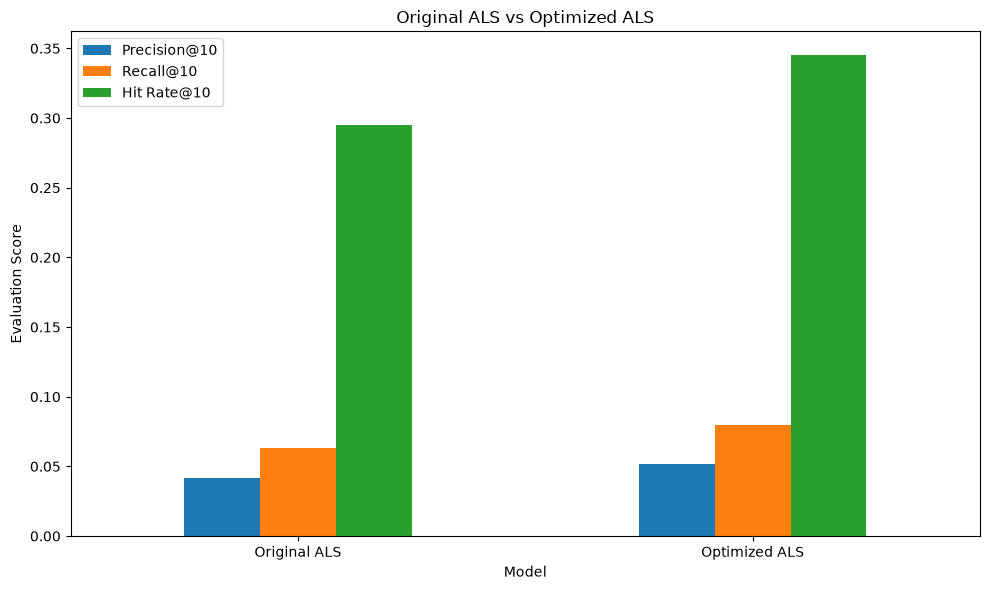

In [55]:
# Visualize ALS performance

plot_data = final_als_comparison.set_index("Model")

plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Original ALS vs Optimized ALS")
plt.ylabel("Evaluation Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "als_optimization_comparison.png"
)

plt.show()

In [56]:
# ==========================================
# STEP 24.1: MLFLOW CONFIGURATION
# ==========================================

import mlflow
import os
from pathlib import Path

# Set project working directory
os.chdir(ROOT)

# Configure local MLflow database
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Create or select experiment
mlflow.set_experiment("Song_Recommendation_System")

print("MLFLOW CONFIGURATION SUCCESSFUL")
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", "Song_Recommendation_System")
print("Database:", ROOT / "mlflow.db")

2026/10/31 21:40:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/31 21:40:43 INFO mlflow.store.db.utils: Updating database tables
2026/10/31 21:40:46 INFO mlflow.tracking.fluent: Experiment with name 'Song_Recommendation_System' does not exist. Creating a new experiment.


MLFLOW CONFIGURATION SUCCESSFUL
Tracking URI: sqlite:///mlflow.db
Experiment: Song_Recommendation_System
Database: E:\FDP_MLOPS\song_m1\mlflow.db


In [57]:
# ==========================================
# STEP 24.2: PREPARE MLFLOW ARTIFACTS
# ==========================================

# Save hyperparameter tuning results
tuning_df.to_csv(
    REPORT_DIR / "als_hyperparameter_tuning.csv",
    index=False
)

# Save final comparison results
final_als_comparison.to_csv(
    REPORT_DIR / "als_final_test_evaluation.csv",
    index=False
)

print("MLflow artifacts prepared!")

for folder in [MODEL_DIR, REPORT_DIR, OUTPUT_DIR]:
    print(folder, ":", folder.exists())

MLflow artifacts prepared!
E:\FDP_MLOPS\song_m1\models : True
E:\FDP_MLOPS\song_m1\reports : True
E:\FDP_MLOPS\song_m1\outputs : True


In [58]:
# ==========================================
# STEP 24.3: MLFLOW EXPERIMENT TRACKING
# ==========================================

def get_metrics(row):
    return {
        "precision_at_10": float(row["Precision@10"]),
        "recall_at_10": float(row["Recall@10"]),
        "hit_rate_at_10": float(row["Hit Rate@10"])
    }


def log_model_run(run_name, params, metrics, artifacts, tags):

    with mlflow.start_run(run_name=run_name) as run:

        mlflow.log_params({
            key: str(value)
            for key, value in params.items()
        })

        mlflow.log_metrics(metrics)
        mlflow.set_tags(tags)

        for artifact in artifacts:

            artifact_path = Path(artifact)

            if artifact_path.exists():
                mlflow.log_artifact(str(artifact_path))
            else:
                print("Artifact not found:", artifact_path)

        print("Logged:", run_name)
        print("Run ID:", run.info.run_id)

        return run.info.run_id


# ------------------------------------------
# 1. BASELINE ALS
# ------------------------------------------

baseline_row = comparison_df[
    comparison_df["Model"] == "ALS"
].iloc[0]

baseline_run_id = log_model_run(
    run_name="ALS_Baseline",
    params={
        "factors": 32,
        "regularization": 0.1,
        "alpha": 20,
        "iterations": 10
    },
    metrics=get_metrics(baseline_row),
    artifacts=[
        MODEL_DIR / "als_collaborative_filtering.npz",
        REPORT_DIR / "als_evaluation_results.csv"
    ],
    tags={
        "model_type": "Collaborative Filtering",
        "evaluation_users": "100",
        "dataset_sample": "500000 interactions"
    }
)


# ------------------------------------------
# 2. CONTENT-BASED MODEL
# ------------------------------------------

content_row = comparison_df[
    comparison_df["Model"] == "Content-Based"
].iloc[0]

content_run_id = log_model_run(
    run_name="TFIDF_Content_Based",
    params={
        "vectorizer": "TF-IDF",
        "similarity": "Cosine Similarity",
        "max_features": 50000,
        "ngram_range": "1,2"
    },
    metrics=get_metrics(content_row),
    artifacts=[
        MODEL_DIR / "tfidf_vectorizer.joblib",
        MODEL_DIR / "song_tfidf_matrix.npz",
        REPORT_DIR / "content_recommendations.csv"
    ],
    tags={
        "model_type": "Content-Based",
        "evaluation_users": "100",
        "dataset_sample": "500000 interactions"
    }
)


# ------------------------------------------
# 3. HYBRID MODEL
# ------------------------------------------

hybrid_row = comparison_df[
    comparison_df["Model"] == "Hybrid"
].iloc[0]

hybrid_run_id = log_model_run(
    run_name="Hybrid_Recommendation",
    params={
        "als_weight": 0.60,
        "content_weight": 0.40,
        "fusion_method": "Reciprocal Rank Fusion"
    },
    metrics=get_metrics(hybrid_row),
    artifacts=[
        REPORT_DIR / "hybrid_recommendations.csv",
        OUTPUT_DIR / "model_comparison.png"
    ],
    tags={
        "model_type": "Hybrid Recommendation",
        "evaluation_users": "100",
        "dataset_sample": "500000 interactions"
    }
)


# ------------------------------------------
# 4. OPTIMIZED ALS MODEL
# ------------------------------------------

optimized_row = final_als_comparison[
    final_als_comparison["Model"] == "Optimized ALS"
].iloc[0]

optimized_params = {
    "factors": int(best_config["factors"]),
    "regularization": float(best_config["regularization"]),
    "alpha": float(best_config["alpha"]),
    "iterations": int(best_config["iterations"])
}

optimized_run_id = log_model_run(
    run_name="ALS_Optimized",
    params=optimized_params,
    metrics=get_metrics(optimized_row),
    artifacts=[
        MODEL_DIR / "als_collaborative_filtering_tuned.npz",
        REPORT_DIR / "als_hyperparameter_tuning.csv",
        REPORT_DIR / "als_final_test_evaluation.csv",
        OUTPUT_DIR / "als_optimization_comparison.png"
    ],
    tags={
        "model_type": "Optimized Collaborative Filtering",
        "evaluation_users": "Up to 1000",
        "dataset_sample": "500000 interactions"
    }
)

print("\nALL FOUR MLFLOW EXPERIMENT RUNS LOGGED!")

Logged: ALS_Baseline
Run ID: fb0a32c3432e4ca182cddc9748ec9fbc
Logged: TFIDF_Content_Based
Run ID: 94f82cd3351a49f79f2be7a259d9db15
Logged: Hybrid_Recommendation
Run ID: 54d5f37f268543629de1b8a608c10525
Logged: ALS_Optimized
Run ID: 644eac2277764678ab7a73648ab1491b

ALL FOUR MLFLOW EXPERIMENT RUNS LOGGED!


In [59]:
# ==========================================
# STEP 24.4: VERIFY MLFLOW EXPERIMENTS
# ==========================================

experiment = mlflow.get_experiment_by_name(
    "Song_Recommendation_System"
)

runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["start_time DESC"]
)

print("MLFLOW EXPERIMENT VERIFICATION")
print("=" * 50)

print("Experiment ID:", experiment.experiment_id)
print("Total recorded runs:", len(runs_df))

display(
    runs_df[
        [
            "run_id",
            "status",
            "metrics.precision_at_10",
            "metrics.recall_at_10",
            "metrics.hit_rate_at_10"
        ]
    ]
)

MLFLOW EXPERIMENT VERIFICATION
Experiment ID: 1
Total recorded runs: 4


,run_id,status,metrics.precision_at_10,metrics.recall_at_10,metrics.hit_rate_at_10
0,644eac2277764678ab7a73648ab1491b,FINISHED,0.0517,0.079908,0.345
1,54d5f37f268543629de1b8a608c10525,FINISHED,0.0840,0.127667,0.510
2,94f82cd3351a49f79f2be7a259d9db15,FINISHED,0.0920,0.110537,0.430
3,fb0a32c3432e4ca182cddc9748ec9fbc,FINISHED,0.0640,0.094129,0.410


In [60]:
# ==========================================
# STEP 25.1: PREPARE MODEL REGISTRY FILES
# ==========================================

import numpy as np
import pandas as pd
import mlflow

from scipy.sparse import save_npz

ALS_MODEL_FILE = MODEL_DIR / "als_collaborative_filtering_tuned.npz"
TRAIN_MATRIX_FILE = PROCESSED_DIR / "train_user_song_matrix.npz"
USER_MAP_FILE = PROCESSED_DIR / "user_index_train.csv"
SONG_MAP_FILE = PROCESSED_DIR / "song_index_train.csv"
CONTENT_META_FILE = PROCESSED_DIR / "content_song_metadata.csv"

# Save optimized ALS model
optimized_als_model.save(str(ALS_MODEL_FILE))

# Save the training interaction matrix
save_npz(str(TRAIN_MATRIX_FILE), train_user_song_matrix)

# Save mappings consistent with the training matrix
pd.DataFrame({
    "user_index": range(len(user_ids)),
    "user_id": [str(x) for x in user_ids]
}).to_csv(USER_MAP_FILE, index=False)

pd.DataFrame({
    "song_index": range(len(song_ids)),
    "song_id": [str(x) for x in song_ids]
}).to_csv(SONG_MAP_FILE, index=False)

# Save content metadata
content_df.to_csv(CONTENT_META_FILE, index=False)

# Verify all artifacts
artifact_files = [
    ALS_MODEL_FILE,
    TRAIN_MATRIX_FILE,
    USER_MAP_FILE,
    SONG_MAP_FILE,
    CONTENT_META_FILE
]

for file in artifact_files:
    print(file.name, ":", file.exists())

assert all(file.exists() for file in artifact_files)

print("\nMODEL REGISTRY FILES READY!")

als_collaborative_filtering_tuned.npz : True
train_user_song_matrix.npz : True
user_index_train.csv : True
song_index_train.csv : True
content_song_metadata.csv : True

MODEL REGISTRY FILES READY!


In [67]:
# ==========================================
# STEP 25.2 FIX: CORRECT MODEL LOADING
# ==========================================

import implicit
import mlflow.pyfunc
import pandas as pd
import json

from scipy.sparse import load_npz


class SongALSMLflowModel(mlflow.pyfunc.PythonModel):

    def load_context(self, context):

        # CORRECTED: Load saved ALS model
        self.model = implicit.load(
            context.artifacts["als_model"]
        )

        # Load interaction matrix
        self.user_items = load_npz(
            context.artifacts["interaction_matrix"]
        )

        # Load user mapping
        users = pd.read_csv(
            context.artifacts["user_mapping"],
            dtype={"user_id": str}
        )

        self.user_to_index = dict(
            zip(users["user_id"], users["user_index"])
        )

        # Load song mapping
        songs = pd.read_csv(
            context.artifacts["song_mapping"],
            dtype={"song_id": str}
        ).sort_values("song_index")

        self.song_ids = songs["song_id"].tolist()

        # Load song metadata
        metadata = pd.read_csv(
            context.artifacts["song_metadata"],
            dtype={"song_id": str}
        ).fillna("")

        metadata = metadata.drop_duplicates("song_id")

        self.metadata = (
            metadata.set_index("song_id").to_dict("index")
        )

    def predict(self, context, model_input, params=None):

        top_n = int(params.get("top_n", 10)) if params else 10

        outputs = []

        for user_id in model_input["user_id"].astype(str):

            if user_id not in self.user_to_index:
                raise ValueError(f"Unknown user ID: {user_id}")

            user_idx = int(self.user_to_index[user_id])

            indices, scores = self.model.recommend(
                userid=user_idx,
                user_items=self.user_items[user_idx],
                N=top_n,
                filter_already_liked_items=True
            )

            recommendations = []

            for idx, score in zip(indices, scores):

                song_id = self.song_ids[int(idx)]
                details = self.metadata.get(song_id, {})

                recommendations.append({
                    "song_id": song_id,
                    "title": details.get("title", ""),
                    "artist": details.get("artist_name", ""),
                    "score": float(score)
                })

            outputs.append({
                "user_id": user_id,
                "recommendations_json": json.dumps(
                    recommendations
                )
            })

        return pd.DataFrame(outputs)


print("CORRECTED MLFLOW PYTHON MODEL CREATED!")

CORRECTED MLFLOW PYTHON MODEL CREATED!


E:\FDP_MLOPS\song_m1\.venv\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [69]:
REGISTERED_MODEL_NAME = "Song_Recommendation_ALS"

In [62]:
# ==========================================
# STEP 25.3: REGISTER MODEL IN MLFLOW
# ==========================================

from mlflow.models.signature import ModelSignature
from mlflow.types.schema import Schema, ColSpec

# Connect notebook to the running MLflow server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

mlflow.set_experiment("Song_Recommendation_System")

REGISTERED_MODEL_NAME = "Song_Recommendation_ALS"

artifact_paths = {
    "als_model": str(ALS_MODEL_FILE.resolve()),
    "interaction_matrix": str(TRAIN_MATRIX_FILE.resolve()),
    "user_mapping": str(USER_MAP_FILE.resolve()),
    "song_mapping": str(SONG_MAP_FILE.resolve()),
    "song_metadata": str(CONTENT_META_FILE.resolve())
}

# Model input/output signature
signature = ModelSignature(
    inputs=Schema([
        ColSpec("string", "user_id")
    ]),
    outputs=Schema([
        ColSpec("string", "user_id"),
        ColSpec("string", "recommendations_json")
    ])
)

input_example = pd.DataFrame({
    "user_id": [str(user_ids[0])]
})

requirements = [
    "mlflow==3.17.2",
    "implicit==0.7.3",
    "numpy==2.4.6",
    "pandas==3.0.6",
    "scipy==1.17.1"
]

with mlflow.start_run(
    run_name="ALS_Model_Registry_Packaging"
) as registry_run:

    model_info = mlflow.pyfunc.log_model(
        name="song_als_recommender",
        python_model=SongALSMLflowModel(),
        artifacts=artifact_paths,
        registered_model_name=REGISTERED_MODEL_NAME,
        input_example=input_example,
        signature=signature,
        pip_requirements=requirements,
        await_registration_for=300
    )

    registry_run_id = registry_run.info.run_id

print("\nMODEL REGISTERED SUCCESSFULLY!")
print("Registered name:", REGISTERED_MODEL_NAME)
print("Model URI:", model_info.model_uri)
print("Run ID:", registry_run_id)

2026/10/31 21:52:12 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
2026/10/31 21:52:12 INFO mlflow.pyfunc: Validating input example against model signature
2026/10/31 21:52:21 WARNING mlflow.models.model: Failed to validate serving input example {
  "dataframe_split": {
    "columns": [
      "u.... Alternatively, you can avoid passing input example and pass model signature instead when logging the model. To ensure the input example is valid prior to serving, please try calling `mlflow.models.predict(model_uri=..., input_data=serving_input, env_manager="uv")` on the model uri and serving input example. A serving input example can be generated from model input example using `mlflo

🏃 View run ALS_Model_Registry_Packaging at: http://127.0.0.1:5000/#/experiments/1/runs/0dafec4a478d4a158f93802c2e5b157f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

MODEL REGISTERED SUCCESSFULLY!
Registered name: Song_Recommendation_ALS
Model URI: models:/m-b91531e04162497bb876284404fa3ea7
Run ID: 0dafec4a478d4a158f93802c2e5b157f


Created version '1' of model 'Song_Recommendation_ALS'.


In [70]:
# ==========================================
# STEP 25.4 FIX: UPDATE MODEL ALIAS
# ==========================================

from mlflow.tracking import MlflowClient

client = MlflowClient()

versions = client.search_model_versions(
    f"name='{REGISTERED_MODEL_NAME}'"
)

latest_version = max(
    versions,
    key=lambda v: int(v.version)
)

client.set_registered_model_alias(
    name=REGISTERED_MODEL_NAME,
    alias="candidate",
    version=latest_version.version
)

print("MODEL ALIAS UPDATED!")
print("Latest version:", latest_version.version)
print("Alias: candidate")

MODEL ALIAS UPDATED!
Latest version: 1
Alias: candidate


In [74]:
# ==========================================
# FIX: DEFINE MODEL URI AND VERIFY REGISTRY
# ==========================================

import mlflow
from mlflow.tracking import MlflowClient

# Connect to MLflow server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

REGISTERED_MODEL_NAME = "Song_Recommendation_ALS"

client = MlflowClient(
    tracking_uri="http://127.0.0.1:5000"
)

# Retrieve registered versions
versions = list(
    client.search_model_versions(
        f"name='{REGISTERED_MODEL_NAME}'"
    )
)

print("REGISTERED MODEL:", REGISTERED_MODEL_NAME)
print("TOTAL VERSIONS:", len(versions))

for v in versions:
    print(
        "Version:", v.version,
        "| Status:", v.status,
        "| Run ID:", v.run_id
    )

assert versions, "No registered model versions found!"

# Check candidate alias
try:
    candidate = client.get_model_version_by_alias(
        REGISTERED_MODEL_NAME,
        "candidate"
    )

    print("\nCandidate version:", candidate.version)
    selected_version = candidate

except Exception as error:
    print("\nCandidate alias not found:", error)

    selected_version = max(
        versions,
        key=lambda v: int(v.version)
    )

# Define model URI using explicit version
model_uri = (
    f"models:/{REGISTERED_MODEL_NAME}/"
    f"{selected_version.version}"
)

print("\nMODEL URI:", model_uri)
print("Registry verification completed!")

REGISTERED MODEL: Song_Recommendation_ALS
TOTAL VERSIONS: 1
Version: 1 | Status: READY | Run ID: 0dafec4a478d4a158f93802c2e5b157f

Candidate version: 1

MODEL URI: models:/Song_Recommendation_ALS/1
Registry verification completed!


In [75]:
from implicit.cpu.als import (
    AlternatingLeastSquares as ALSModelClass
)

print("ALS class:", ALSModelClass)
print("Has load method:", hasattr(ALSModelClass, "load"))

test_model = ALSModelClass.load(
    str(ALS_MODEL_FILE)
)

print("\nALS MODEL LOADED SUCCESSFULLY!")
print("User factors:", test_model.user_factors.shape)
print("Song factors:", test_model.item_factors.shape)

ALS class: <class 'implicit.cpu.als.AlternatingLeastSquares'>
Has load method: True

ALS MODEL LOADED SUCCESSFULLY!
User factors: (10354, 64)
Song factors: (97405, 64)


In [76]:
import mlflow
import mlflow.pyfunc
import pandas as pd
import json
from scipy.sparse import load_npz


class SongALSMLflowModel(mlflow.pyfunc.PythonModel):

    def load_context(self, context):

        from implicit.cpu.als import (
            AlternatingLeastSquares as ALSModelClass
        )

        # Correct ALS model loader
        self.model = ALSModelClass.load(
            context.artifacts["als_model"]
        )

        self.user_items = load_npz(
            context.artifacts["interaction_matrix"]
        )

        users = pd.read_csv(
            context.artifacts["user_mapping"],
            dtype={"user_id": str}
        )

        self.user_to_index = dict(
            zip(users["user_id"], users["user_index"])
        )

        songs = pd.read_csv(
            context.artifacts["song_mapping"],
            dtype={"song_id": str}
        ).sort_values("song_index")

        self.song_ids = songs["song_id"].tolist()

        metadata = pd.read_csv(
            context.artifacts["song_metadata"],
            dtype={"song_id": str}
        ).fillna("")

        metadata = metadata.drop_duplicates("song_id")

        self.metadata = metadata.set_index(
            "song_id"
        ).to_dict("index")

    def predict(
        self,
        context,
        model_input: pd.DataFrame,
        params=None
    ) -> pd.DataFrame:

        top_n = int(params.get("top_n", 10)) if params else 10

        results = []

        for user_id in model_input["user_id"].astype(str):

            if user_id not in self.user_to_index:
                raise ValueError(f"Unknown user: {user_id}")

            user_idx = int(self.user_to_index[user_id])

            indices, scores = self.model.recommend(
                userid=user_idx,
                user_items=self.user_items[user_idx],
                N=top_n,
                filter_already_liked_items=True
            )

            recommendations = []

            for idx, score in zip(indices, scores):

                song_id = self.song_ids[int(idx)]
                details = self.metadata.get(song_id, {})

                recommendations.append({
                    "song_id": song_id,
                    "title": details.get("title", ""),
                    "artist": details.get("artist_name", ""),
                    "score": float(score)
                })

            results.append({
                "user_id": user_id,
                "recommendations_json": json.dumps(
                    recommendations
                )
            })

        return pd.DataFrame(results)


print("CORRECTED MLFLOW MODEL CLASS READY!")

CORRECTED MLFLOW MODEL CLASS READY!


In [77]:
from mlflow.tracking import MlflowClient

client = MlflowClient(
    tracking_uri="http://127.0.0.1:5000"
)

versions = client.search_model_versions(
    f"name='{REGISTERED_MODEL_NAME}'"
)

latest_version = max(
    versions,
    key=lambda v: int(v.version)
)

client.set_registered_model_alias(
    name=REGISTERED_MODEL_NAME,
    alias="candidate",
    version=latest_version.version
)

print("Latest version:", latest_version.version)
print("Alias updated: candidate")

Latest version: 1
Alias updated: candidate


In [79]:
# ==========================================
# DIAGNOSIS: MLFLOW MODEL VERSION
# ==========================================

import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("http://127.0.0.1:5000")

client = MlflowClient(
    tracking_uri="http://127.0.0.1:5000"
)

model_name = "Song_Recommendation_ALS"

versions = list(
    client.search_model_versions(
        f"name='{model_name}'"
    )
)

print("REGISTERED MODEL:", model_name)
print("TOTAL VERSIONS:", len(versions))

for v in sorted(versions, key=lambda x: int(x.version)):
    print("--------------------------------")
    print("Version:", v.version)
    print("Status:", v.status)
    print("Run ID:", v.run_id)
    print("Source:", v.source)

candidate = client.get_model_version_by_alias(
    model_name,
    "candidate"
)

print("\nCANDIDATE ALIAS VERSION:", candidate.version)
print("CANDIDATE RUN ID:", candidate.run_id)

print("\nDIAGNOSTIC COMPLETED!")

REGISTERED MODEL: Song_Recommendation_ALS
TOTAL VERSIONS: 1
--------------------------------
Version: 1
Status: READY
Run ID: 0dafec4a478d4a158f93802c2e5b157f
Source: models:/m-b91531e04162497bb876284404fa3ea7

CANDIDATE ALIAS VERSION: 1
CANDIDATE RUN ID: 0dafec4a478d4a158f93802c2e5b157f

DIAGNOSTIC COMPLETED!


In [ ]:
from implicit.cpu.als import AlternatingLeastSquares as ALSModelClass

self.model = ALSModelClass.load(
    context.artifacts["als_model"]
)

In [81]:
# ==================================================
# STEP 28: RESTORE DATA AND PREPARE DRIFT DATASETS
# ==================================================

import sqlite3
import numpy as np
import pandas as pd

from pathlib import Path

# 1. Project paths
ROOT = Path(r"E:\FDP_MLOPS\song_m1")

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
REPORT_DIR = ROOT / "reports"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_FILE = PROCESSED_DIR / "song_interactions_clean.csv"
METADATA_CSV = PROCESSED_DIR / "song_metadata_sample.csv"
METADATA_DB = RAW_DIR / "track_metadata.db"

assert CLEAN_FILE.exists(), "Clean interaction CSV missing!"
assert METADATA_DB.exists(), "SQLite metadata database missing!"

# 2. Load cleaned interactions
df_clean = pd.read_csv(
    CLEAN_FILE,
    dtype={"user_id": str, "song_id": str}
)

print("Clean interactions loaded:", df_clean.shape)

# 3. Load existing metadata or extract it from SQLite
if METADATA_CSV.exists():

    metadata_df = pd.read_csv(
        METADATA_CSV,
        dtype={"song_id": str}
    )

    required = {
        "song_id", "title", "artist_name",
        "duration", "artist_familiarity",
        "artist_hotttnesss", "year"
    }

    if not required.issubset(metadata_df.columns):
        raise ValueError("Metadata CSV has an incomplete schema.")

    print("Existing metadata loaded:", metadata_df.shape)

else:

    song_ids_list = (
        df_clean["song_id"]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    metadata_parts = []

    print("Extracting metadata for", len(song_ids_list), "songs...")

    conn = sqlite3.connect(str(METADATA_DB))

    try:
        for start in range(0, len(song_ids_list), 800):

            batch = song_ids_list[start:start + 800]
            placeholders = ",".join(["?"] * len(batch))

            query = f"""
                SELECT
                    song_id,
                    title,
                    release,
                    artist_id,
                    artist_name,
                    duration,
                    artist_familiarity,
                    artist_hotttnesss,
                    year
                FROM songs
                WHERE song_id IN ({placeholders})
            """

            part = pd.read_sql_query(
                query, conn, params=batch
            )

            metadata_parts.append(part)

            if (start // 800 + 1) % 10 == 0:
                print(
                    "Processed:",
                    min(start + 800, len(song_ids_list)),
                    "/",
                    len(song_ids_list)
                )

    finally:
        conn.close()

    metadata_df = pd.concat(
        metadata_parts,
        ignore_index=True
    ).drop_duplicates("song_id")

    metadata_df.to_csv(
        METADATA_CSV,
        index=False
    )

    print("Metadata saved:", metadata_df.shape)

assert not metadata_df.empty

# 4. Aggregate interactions
interaction_df = (
    df_clean.groupby(
        ["user_id", "song_id"],
        as_index=False
    )
    .agg(play_count=("play_count", "sum"))
)

# 5. Recreate per-user training/test split
rng = np.random.default_rng(42)

train_parts = []
test_parts = []

for _, user_rows in interaction_df.groupby(
    "user_id", sort=False
):

    if len(user_rows) < 2:
        train_parts.append(user_rows)
        continue

    order = rng.permutation(len(user_rows))

    test_count = max(
        1, int(round(len(user_rows) * 0.20))
    )
    test_count = min(
        test_count, len(user_rows) - 1
    )

    test_parts.append(
        user_rows.iloc[order[:test_count]]
    )

    train_parts.append(
        user_rows.iloc[order[test_count:]]
    )

train_df = pd.concat(
    train_parts, ignore_index=True
)

test_df = (
    pd.concat(test_parts, ignore_index=True)
    if test_parts
    else interaction_df.iloc[0:0].copy()
)

# 6. Prepare song metadata
drift_metadata = (
    metadata_df[
        [
            "song_id",
            "duration",
            "artist_familiarity",
            "artist_hotttnesss",
            "year"
        ]
    ]
    .drop_duplicates("song_id")
    .copy()
)

# 7. Build reference and current datasets
def prepare_drift_data(interactions):

    data = interactions[
        ["song_id", "play_count"]
    ].copy()

    data["song_id"] = data["song_id"].astype(str)

    data = data.merge(
        drift_metadata,
        on="song_id",
        how="left",
        validate="many_to_one"
    )

    data["metadata_matched"] = (
        data["duration"].notna().astype(int)
    )

    numeric_columns = [
        "play_count",
        "duration",
        "artist_familiarity",
        "artist_hotttnesss",
        "year"
    ]

    for column in numeric_columns:
        data[column] = pd.to_numeric(
            data[column],
            errors="coerce"
        )

    return data[
        numeric_columns + ["metadata_matched"]
    ].copy()


reference_data = prepare_drift_data(train_df)
current_data = prepare_drift_data(test_df)

# 8. Final verification
print("\n" + "=" * 50)
print("DRIFT DATA PREPARATION COMPLETED!")
print("=" * 50)

print("Metadata records:", len(metadata_df))
print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Reference shape:", reference_data.shape)
print("Current shape:", current_data.shape)

print("\nAll required variables available:")

for name in [
    "metadata_df",
    "train_df",
    "test_df",
    "reference_data",
    "current_data"
]:
    print(name, ":", name in globals())

Clean interactions loaded: (500000, 3)
Extracting metadata for 108797 songs...
Processed: 8000 / 108797
Processed: 16000 / 108797
Processed: 24000 / 108797
Processed: 32000 / 108797
Processed: 40000 / 108797
Processed: 48000 / 108797
Processed: 56000 / 108797
Processed: 64000 / 108797
Processed: 72000 / 108797
Processed: 80000 / 108797
Processed: 88000 / 108797
Processed: 96000 / 108797
Processed: 104000 / 108797
Metadata saved: (108797, 9)

DRIFT DATA PREPARATION COMPLETED!
Metadata records: 108797
Training records: 400103
Testing records: 99897
Reference shape: (400103, 6)
Current shape: (99897, 6)

All required variables available:
metadata_df : True
train_df : True
test_df : True
reference_data : True
current_data : True
